In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

DATA_FILE = Path("../data/engineered_job_placement_data.csv")
DATA_DIR = Path("../data")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
display(df.head())
print(df["status"].value_counts())

Dataset shape: (50000, 31)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,experience_category,academic_performance_band,skills_match_level,average_interview_score,interview_performance_category
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,15.0,No,18.0,Not Willing,Not Placed,Junior,High,Medium,70.754233,Medium
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,0.0,Unknown,0.0,Not Willing,Not Placed,Fresher,Medium,Medium,62.532418,Medium
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,0.0,No,3.0,Not Willing,Placed,Junior,High,Medium,70.175622,Medium
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,0.0,Yes,6.0,Unknown,Not Placed,Fresher,High,Medium,64.539376,Medium
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,0.0,No,3.0,Willing,Not Placed,Fresher,High,High,65.146274,Medium


status
Not Placed    34870
Placed        15130
Name: count, dtype: int64


### Separate features and target

In [20]:
X = df.drop(columns=["status"]).copy()
y = df["status"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(y.value_counts().to_frame("Count"))

Features shape: (50000, 30)
Target shape: (50000,)


,Count
status,
Not Placed,34870
Placed,15130


### Split into training and testing sets

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\\nTraining target distribution (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\\nTesting target distribution (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (40000, 30)
Testing features: (10000, 30)
\nTraining target distribution (%):


status
Not Placed    69.74
Placed        30.26
Name: proportion, dtype: float64

\nTesting target distribution (%):


status
Not Placed    69.74
Placed        30.26
Name: proportion, dtype: float64

### Build preprocessing pipeline

In [22]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\\nCategorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)
print("Preprocessor created successfully.")

Numerical features: ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'average_interview_score']
\nCategorical features: ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_category', 'academic_performance_band', 'skills_match_level', 'interview_performance_category']
Preprocessor created successfully.


/var/folders/kn/d0lcr0v10y38q1c53h2w1y300000gn/T/ipykernel_4760/2989977775.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### Train and compare five models

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=42)
}

results = []
trained_models = {}

for name, classifier in models.items():
    print(f"Training {name}...")
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, pos_label="Placed", zero_division=0),
        "Recall": recall_score(y_test, predictions, pos_label="Placed", zero_division=0),
        "F1_Score": f1_score(y_test, predictions, pos_label="Placed", zero_division=0)
    })
    trained_models[name] = pipeline

comparison_df = pd.DataFrame(results).sort_values(
    by="F1_Score", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training K-Nearest Neighbors...
Training Linear SVM...


,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.8941,0.8758,0.7574,0.8123
1,Linear SVM,0.8816,0.8211,0.7783,0.7991
2,Logistic Regression,0.8814,0.8199,0.7792,0.7991
3,Decision Tree,0.8286,0.7101,0.7327,0.7212
4,K-Nearest Neighbors,0.8160,0.6869,0.7201,0.7031


### Evaluate the selected Random Forest model

First 10 actual outcomes:
['Not Placed', 'Not Placed', 'Placed', 'Placed', 'Placed', 'Not Placed', 'Not Placed', 'Placed', 'Placed', 'Placed']

First 10 predicted outcomes:
['Not Placed' 'Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Not Placed'
 'Not Placed' 'Not Placed' 'Placed' 'Placed']

Classification report:
              precision    recall  f1-score   support

  Not Placed       0.90      0.95      0.93      6974
      Placed       0.88      0.76      0.81      3026

    accuracy                           0.89     10000
   macro avg       0.89      0.86      0.87     10000
weighted avg       0.89      0.89      0.89     10000

Confusion matrix:
[[6649  325]
 [ 734 2292]]


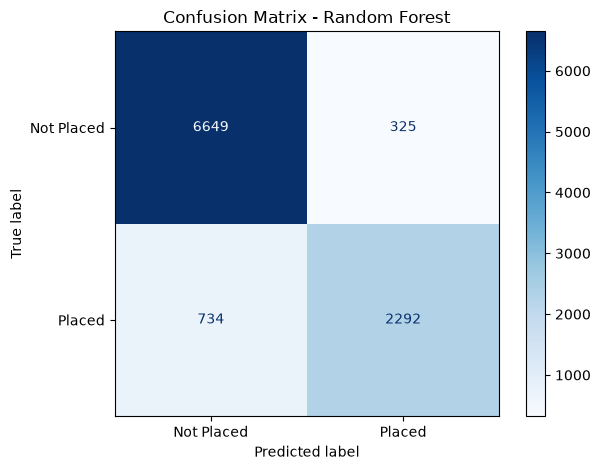

In [24]:
best_model = trained_models["Random Forest"]
y_pred = best_model.predict(X_test)

print("First 10 actual outcomes:")
print(y_test.head(10).tolist())
print("\n" + "First 10 predicted outcomes:")
print(y_pred[:10])

print("\n" + "Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["Not Placed", "Placed"])
print("Confusion matrix:")
print(cm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Not Placed", "Placed"]
)
cm_display.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

### Placement probabilities and ROC-AUC

In [25]:
if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(X_test)
    placed_index = list(best_model.classes_).index("Placed")
    placed_probability = probabilities[:, placed_index]

    placement_results = pd.DataFrame({
        "Actual_Status": y_test,
        "Predicted_Status": best_model.predict(X_test),
        "Placement_Probability": (placed_probability * 100).round(2)
    }, index=y_test.index)

    display(placement_results.head(10))

    y_test_binary = (y_test == "Placed").astype(int)
    roc_auc = roc_auc_score(y_test_binary, placed_probability)
    print("Random Forest ROC-AUC:", round(roc_auc, 4))
else:
    print("The selected model does not support predict_proba.")

,Actual_Status,Predicted_Status,Placement_Probability
46767,Not Placed,Not Placed,39.0
29649,Not Placed,Not Placed,4.0
28994,Placed,Not Placed,44.0
17805,Placed,Not Placed,45.0
32509,Placed,Placed,71.0
27404,Not Placed,Not Placed,11.0
30490,Not Placed,Not Placed,39.0
1155,Placed,Not Placed,43.0
9623,Placed,Placed,51.0
41900,Placed,Placed,61.0


Random Forest ROC-AUC: 0.9587


### Save models and reports

In [26]:
joblib.dump(trained_models, MODEL_DIR / "placement_models.pkl")
comparison_df.to_csv(DATA_DIR / "model_comparison.csv", index=False)

if "placement_results" in globals():
    placement_results.to_csv(DATA_DIR / "placement_prediction_results.csv", index=True)

print("Models saved to:", MODEL_DIR / "placement_models.pkl")
print("Model comparison saved to:", DATA_DIR / "model_comparison.csv")
print("Best model by F1-score:", comparison_df.iloc[0]["Model"])
display(comparison_df.round(4))

Models saved to: ../models/placement_models.pkl
Model comparison saved to: ../data/model_comparison.csv
Best model by F1-score: Random Forest


,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.8941,0.8758,0.7574,0.8123
1,Linear SVM,0.8816,0.8211,0.7783,0.7991
2,Logistic Regression,0.8814,0.8199,0.7792,0.7991
3,Decision Tree,0.8286,0.7101,0.7327,0.7212
4,K-Nearest Neighbors,0.8160,0.6869,0.7201,0.7031


## Analyst Tasks (EDA & ML Analytics)

In [27]:
#Candidate Performance Analysis

#Academic scores vs placement outcome
academic_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage"
]

academic_analysis = df.groupby("status")[academic_columns].mean()

print(academic_analysis.round(2))

            ssc_percentage  hsc_percentage  degree_percentage
status                                                       
Not Placed           70.03           72.07              74.04
Placed               69.97           72.03              73.93


The average academic scores are almost identical for placed and not-placed candidates in this dataset.

Conclusion: SSC, HSC, and degree percentages alone do not appear to distinguish placed candidates from not-placed candidates very well in this dataset. Other features, such as interview performance, skills match, and experience, may provide more useful information.

This describes an association in your dataset; it doesn't prove that academic scores have no effect on placement in general.

In [28]:
#Skills match vs interview performance

skills_interview_analysis = df.groupby(
    "skills_match_level"
)[
    [
        "skills_match_percentage",
        "average_interview_score"
    ]
].mean()

print(skills_interview_analysis.round(2))


                    skills_match_percentage  average_interview_score
skills_match_level                                                  
High                                  87.47                    66.09
Low                                   54.26                    66.00
Medium                                70.88                    66.03


As expected, the average skills-match percentage increases from Low to High. However, the average interview score stays almost the same across all three groups, around 66.

Conclusion: In this dataset, higher skills-match percentages are not associated with a meaningful difference in average interview scores. Skills match and interview performance may capture different aspects of a candidate's suitability.

This is a comparison of group averages; it doesn't establish whether the two variables have a relationship at an individual-candidate level.

In [29]:
#Certification impact on placement

certification_analysis = df.groupby(
    "certifications_count"
).agg(
    total_candidates=("status", "size"),
    placed_candidates=(
        "status",
        lambda x: (x == "Placed").sum()
    )
)

certification_analysis["placement_rate"] = (
    certification_analysis["placed_candidates"]
    / certification_analysis["total_candidates"]
    * 100
)

print(certification_analysis.round(2))

                      total_candidates  placed_candidates  placement_rate
certifications_count                                                     
0                                12340               3765           30.51
1                                17233               5207           30.22
2                                12096               3638           30.08
3                                 5632               1717           30.49
4                                 1984                615           31.00
5                                  557                145           26.03
6                                  116                 35           30.17
7                                   33                  5           15.15
8                                    9                  3           33.33


- Candidates with 4 certifications have the highest placement rate among groups with a reasonable number of candidates: 31.00%.
- Candidates with 0 certifications also have a similar placement rate of 30.51%.
- The placement rates for 0–4 certifications are very similar.
- The rates for 5–8 certifications fluctuate, but those groups have fewer candidates. For example, only 9 candidates have 8 certifications, so that group's 33.33% rate is not reliable evidence of a general trend.

Conclusion: In this dataset, the number of certifications does not show a clear relationship with placement success. Having more certifications does not automatically mean a higher placement rate.

In [30]:
#Acceptance rate by company tier
company_tier_analysis = df.groupby("company_tier").agg(
    total_candidates=("status", "size"),
    placed_candidates=("status", lambda x: (x == "Placed").sum())
)

company_tier_analysis["placement_rate"] = (
    company_tier_analysis["placed_candidates"]
    / company_tier_analysis["total_candidates"]
    * 100
)

print(company_tier_analysis.round(2))

              total_candidates  placed_candidates  placement_rate
company_tier                                                     
Tier 1                   19305               5779           29.94
Tier 2                   18483               5622           30.42
Tier 3                   12212               3729           30.54


Interpretation: Placement rates are very similar across all three tiers. Tier 3 has the highest rate at 30.54%, but the difference between the highest and lowest rates is only 0.60 percentage points.

In [31]:
#Experience vs placement success

experience_analysis = df.groupby("years_of_experience").agg(
    total_candidates=("status", "size"),
    placed_candidates=("status", lambda x: (x == "Placed").sum())
)

experience_analysis["placement_rate"] = (
    experience_analysis["placed_candidates"]
    / experience_analysis["total_candidates"]
    * 100
)

print(experience_analysis.round(2))

                     total_candidates  placed_candidates  placement_rate
years_of_experience                                                     
0                               14952               2061           13.78
1                               13508               3259           24.13
2                                9966               3597           36.09
3                                6538               3204           49.01
4                                3548               2048           57.72
5                                1488                961           64.58


Interpretation: The observed placement rate increases as years of experience increase in this dataset. However, the number of candidates also decreases at higher experience levels, so those rates are based on smaller groups.

In [32]:
#Interview score vs placement probability

placement_probability = probabilities[:, placed_index] * 100
probability_analysis = X_test[
    ["average_interview_score", "interview_performance_category"]
].copy()

probability_analysis["placement_probability"] = placement_probability
probability_analysis["actual_status"] = y_test

interview_probability_analysis = probability_analysis.groupby(
    "interview_performance_category"
).agg(
    avg_interview_score=("average_interview_score", "mean"),
    avg_placement_probability=("placement_probability", "mean"),
    actual_placement_rate=(
        "actual_status",
        lambda x: (x == "Placed").mean() * 100
    ),
    candidates=("actual_status", "size")
)

print(interview_probability_analysis.round(2))


                                avg_interview_score  \
interview_performance_category                        
High                                          77.68   
Low                                           56.84   
Medium                                        66.94   

                                avg_placement_probability  \
interview_performance_category                              
High                                                53.70   
Low                                                  7.83   
Medium                                              32.77   

                                actual_placement_rate  candidates  
interview_performance_category                                     
High                                            54.51         743  
Low                                              7.18        1615  
Medium                                          32.78        7642  


### Interview Score vs Placement Probability

The analysis shows a positive relationship between interview performance and placement success. Candidates in the High performance category had an average interview score of 77.68 and an actual placement rate of 54.51%. The Medium category had a placement rate of 32.78%, while the Low category had a placement rate of 7.18%.

The Random Forest model's predicted placement probabilities followed a similar pattern. This suggests that interview performance is a useful indicator of placement outcomes in this dataset. However, this relationship does not necessarily imply causation.

In [33]:
#Employability test score analysis

employability_analysis = df.groupby("status")[
    ["technical_score", "aptitude_score", "communication_score"]
].mean()

print(employability_analysis.round(2))


            technical_score  aptitude_score  communication_score
status                                                          
Not Placed            64.88           63.74                65.46
Placed                75.30           64.59                67.57


### Employability Test Score Analysis

The analysis compared technical, aptitude, and communication scores between placed and not-placed candidates. Placed candidates had a higher average technical score of 75.30, compared with 64.88 for candidates who were not placed. The differences in aptitude and communication scores were smaller.

Technical performance showed the strongest difference between the two groups, suggesting that it may be an important indicator of placement outcomes in this dataset. Further statistical analysis would be required to establish the significance of these differences.